# Arena Forage Visualization

2D scent heatmap and rendered angled overview with rodent in neutral position.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

if sys.platform == "darwin":
    os.environ["MUJOCO_GL"] = "glfw"
else:
    os.environ["MUJOCO_GL"] = "egl"

import jax
import jax.numpy as jp
import mujoco
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from pathlib import Path

%matplotlib inline
%config InlineBackend.figure_format='retina'

## Configuration

In [2]:
# Treat parameters
NUM_TREATS = 10
TREAT_SPHERE_RADIUS = 0.06
TREAT_HEIGHT = 0.03
MIN_SPAWN_RADIUS = 1.0
MAX_SPAWN_RADIUS = 2.0
SCENT_SIGMA = 0.2
SEED = 42

# Scent grid rendering
SCENT_GRID_EXTENT = 5.0  # half-size of the scent tile grid (meters), matches arena
SCENT_GRID_RESOLUTION = 100  # tiles per axis
SCENT_THRESHOLD = 0  # min scent to render a tile (skip near-zero)

# Toggle individual treats on/off to see scent update
COLLECTED_MASK = [False] * NUM_TREATS

# Output
OUTPUT_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/arena_forage")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Sample Treat Positions

In [3]:
# Sample treat positions using jittered grid (stratified sampling)
rng = jax.random.PRNGKey(SEED)
angle_rng, radius_rng = jax.random.split(rng)

# Angular: divide circle into NUM_TREATS equal sectors, jitter within each
sector_width = 2 * np.pi / NUM_TREATS
base_angles = np.linspace(0, 2 * np.pi, NUM_TREATS, endpoint=False)
angle_jitter = jax.random.uniform(
    angle_rng, (NUM_TREATS,), minval=0, maxval=sector_width
)
angles = base_angles + angle_jitter

# Radial: stratified bands from MIN_SPAWN_RADIUS to MAX_SPAWN_RADIUS
band_edges = np.linspace(MIN_SPAWN_RADIUS, MAX_SPAWN_RADIUS, NUM_TREATS + 1)
band_lo = band_edges[:-1]
band_hi = band_edges[1:]
band_order = jax.random.permutation(jax.random.PRNGKey(SEED + 1), NUM_TREATS)
band_lo = band_lo[band_order]
band_hi = band_hi[band_order]
u = jax.random.uniform(radius_rng, (NUM_TREATS,))
radii = jp.sqrt(band_lo**2 + u * (band_hi**2 - band_lo**2))

treat_positions = np.array(
    jp.stack(
        [
            radii * jp.cos(angles),
            radii * jp.sin(angles),
            jp.full((NUM_TREATS,), TREAT_HEIGHT),
        ],
        axis=-1,
    )
)
collected = np.array(COLLECTED_MASK, dtype=bool)

print("Treat positions (jittered grid):")
for i, (pos, col) in enumerate(zip(treat_positions, collected)):
    status = "COLLECTED" if col else "active"
    print(f"  treat_{i}: ({pos[0]:+.3f}, {pos[1]:+.3f}, {pos[2]:.3f})  [{status}]")

Treat positions (jittered grid):
  treat_0: (+1.015, +0.351, 0.030)  [active]
  treat_1: (+1.071, +1.160, 0.030)  [active]
  treat_2: (-0.354, +1.374, 0.030)  [active]
  treat_3: (-1.317, +1.406, 0.030)  [active]
  treat_4: (-1.759, +0.431, 0.030)  [active]
  treat_5: (-1.221, -0.503, 0.030)  [active]
  treat_6: (-0.535, -0.999, 0.030)  [active]
  treat_7: (-0.220, -1.191, 0.030)  [active]
  treat_8: (+0.563, -1.650, 0.030)  [active]
  treat_9: (+1.627, -0.269, 0.030)  [active]


## Compute Scent Grid

In [4]:
# Build 2D scent intensity grid
grid_1d = np.linspace(-SCENT_GRID_EXTENT, SCENT_GRID_EXTENT, SCENT_GRID_RESOLUTION)
gx, gy = np.meshgrid(grid_1d, grid_1d)
scent_grid = np.zeros_like(gx)

for i in range(NUM_TREATS):
    if collected[i]:
        continue
    tx, ty = treat_positions[i, 0], treat_positions[i, 1]
    dist2 = (gx - tx) ** 2 + (gy - ty) ** 2
    scent_grid += np.exp(-dist2 / (2 * SCENT_SIGMA**2))

print(f"Scent grid shape: {scent_grid.shape}")
print(f"Scent range: [{scent_grid.min():.4f}, {scent_grid.max():.4f}]")
print(f"Tiles above threshold: {(scent_grid > SCENT_THRESHOLD).sum()} / {scent_grid.size}")

Scent grid shape: (100, 100)
Scent range: [0.0000, 1.2856]
Tiles above threshold: 10000 / 10000


## 2D Scent Heatmap

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/arena_forage/arena_forage_scent_field.[pdf|svg|png]


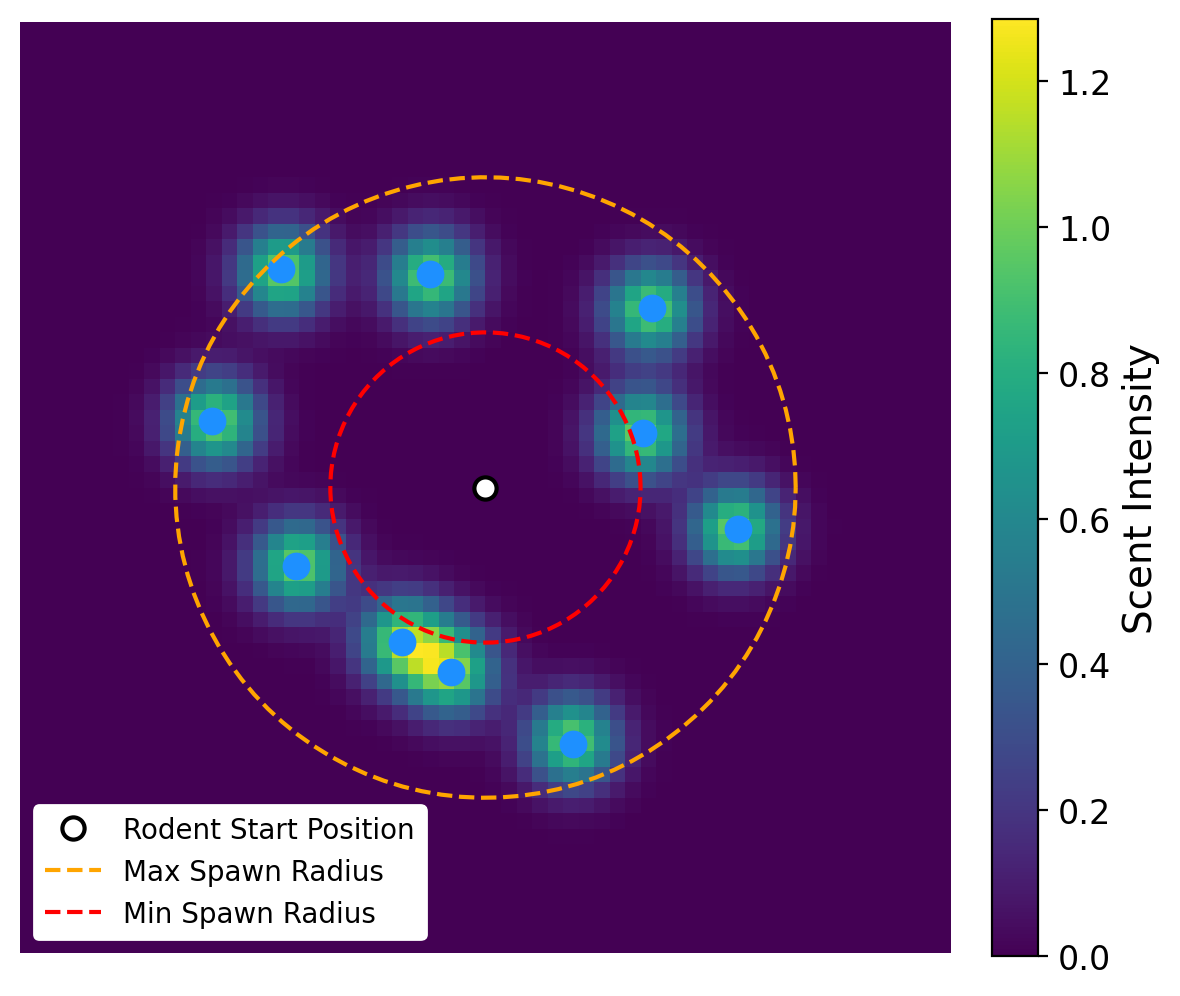

In [5]:
extent = MAX_SPAWN_RADIUS * 1.5
vmax = max(float(scent_grid.max()), 1.0)

fig, ax = plt.subplots(figsize=(6, 6))

# Scent heatmap
im = ax.imshow(
    scent_grid,
    extent=[
        -SCENT_GRID_EXTENT,
        SCENT_GRID_EXTENT,
        -SCENT_GRID_EXTENT,
        SCENT_GRID_EXTENT,
    ],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=vmax,
    aspect="equal",
)

# Treat positions
for i in range(NUM_TREATS):
    color = "gray" if collected[i] else "dodgerblue"
    marker = "x" if collected[i] else "o"
    ax.plot(
        treat_positions[i, 0],
        treat_positions[i, 1],
        marker=marker,
        color=color,
        markersize=8,
        markeredgewidth=2,
        linestyle="None",
    )

# Rodent start position
ax.plot(
    0,
    0,
    "o",
    color="white",
    markersize=8,
    markeredgecolor="black",
    markeredgewidth=1.5,
    linestyle="None",
    label="Rodent Start Position",
    zorder=5,
)

# Spawn radius circles
theta = np.linspace(0, 2 * np.pi, 100)
ax.plot(
    MAX_SPAWN_RADIUS * np.cos(theta),
    MAX_SPAWN_RADIUS * np.sin(theta),
    color="orange",
    linestyle="--",
    alpha=1.0,
    linewidth=1.5,
    label="Max Spawn Radius",
)
ax.plot(
    MIN_SPAWN_RADIUS * np.cos(theta),
    MIN_SPAWN_RADIUS * np.sin(theta),
    "r--",
    alpha=1.0,
    linewidth=1.5,
    label="Min Spawn Radius",
)

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.axis("off")

ax.legend(
    fontsize=10,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="white",
    framealpha=1.0,
)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Scent Intensity", fontsize=14)
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()

save_name = "arena_forage_scent_field"
fig.savefig(OUTPUT_DIR / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / f"{save_name}.png", bbox_inches="tight", dpi=300)
print(f"Saved to {OUTPUT_DIR / save_name}.[pdf|svg|png]")

plt.show()

## Build MuJoCo Model with Rodent, Treats, and Scent Tiles

In [8]:
from scamper.environment.rodent import consts

# Load arena spec
spec = mujoco.MjSpec.from_file(str(consts.ARENA_XML_PATH))

# Attach rodent in neutral pose at the centre
rodent_spec = mujoco.MjSpec.from_file(str(consts.RODENT_NO_TAIL_COLLISION_XML))

# Convert motors to torque actuators (matches ArenaForage default)
for actuator in rodent_spec.actuators:
    if actuator.forcerange.size >= 2:
        actuator.gainprm[0] = actuator.forcerange[1]
    actuator.biastype = mujoco.mjtBias.mjBIAS_NONE
    actuator.biasprm = np.zeros((10, 1))

spawn_frame = spec.worldbody.add_frame(pos=[0.0, 0.0, 0.0], quat=[1, 0, 0, 0])
spawn_body = spawn_frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")

# Add treat spheres
for i in range(NUM_TREATS):
    if collected[i]:
        pos = [0, 0, -10]
    else:
        pos = treat_positions[i].tolist()
    spec.worldbody.add_geom(
        name=f"treat_{i}",
        type=mujoco.mjtGeom.mjGEOM_SPHERE,
        pos=pos,
        size=[TREAT_SPHERE_RADIUS],
        rgba=[0.2, 0.4, 1.0, 0.8],
        contype=0,
        conaffinity=0,
    )

# Add scent floor tiles
tile_size = SCENT_GRID_EXTENT / SCENT_GRID_RESOLUTION
tile_count = 0
for row in range(SCENT_GRID_RESOLUTION):
    for col in range(SCENT_GRID_RESOLUTION):
        intensity = scent_grid[row, col]
        if intensity < SCENT_THRESHOLD:
            continue
        clamped = min(intensity, 1.0)
        rgba = list(cm.viridis(clamped))
        rgba[3] = clamped * 0.6
        cx = grid_1d[col]
        cy = grid_1d[row]
        spec.worldbody.add_geom(
            name=f"scent_{tile_count}",
            type=mujoco.mjtGeom.mjGEOM_BOX,
            pos=[cx, cy, 0],
            size=[tile_size, tile_size, 0.0001],
            rgba=rgba,
            contype=0,
            conaffinity=0,
        )
        tile_count += 1

# Add overhead light
spec.worldbody.add_light(pos=[0, 0, 10], dir=[0, 0, -1])

# Compile
model = spec.compile()
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

print(f"Added {tile_count} scent tiles, {NUM_TREATS} treat spheres, and rodent")
print(f"Total geoms: {model.ngeom}, Total bodies: {model.nbody}")

Added 10000 scent tiles, 10 treat spheres, and rodent
Total geoms: 10111, Total bodies: 68


## Rendered Angled Overview

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/arena_forage/arena_forage_angled_overview.[pdf|svg|png]


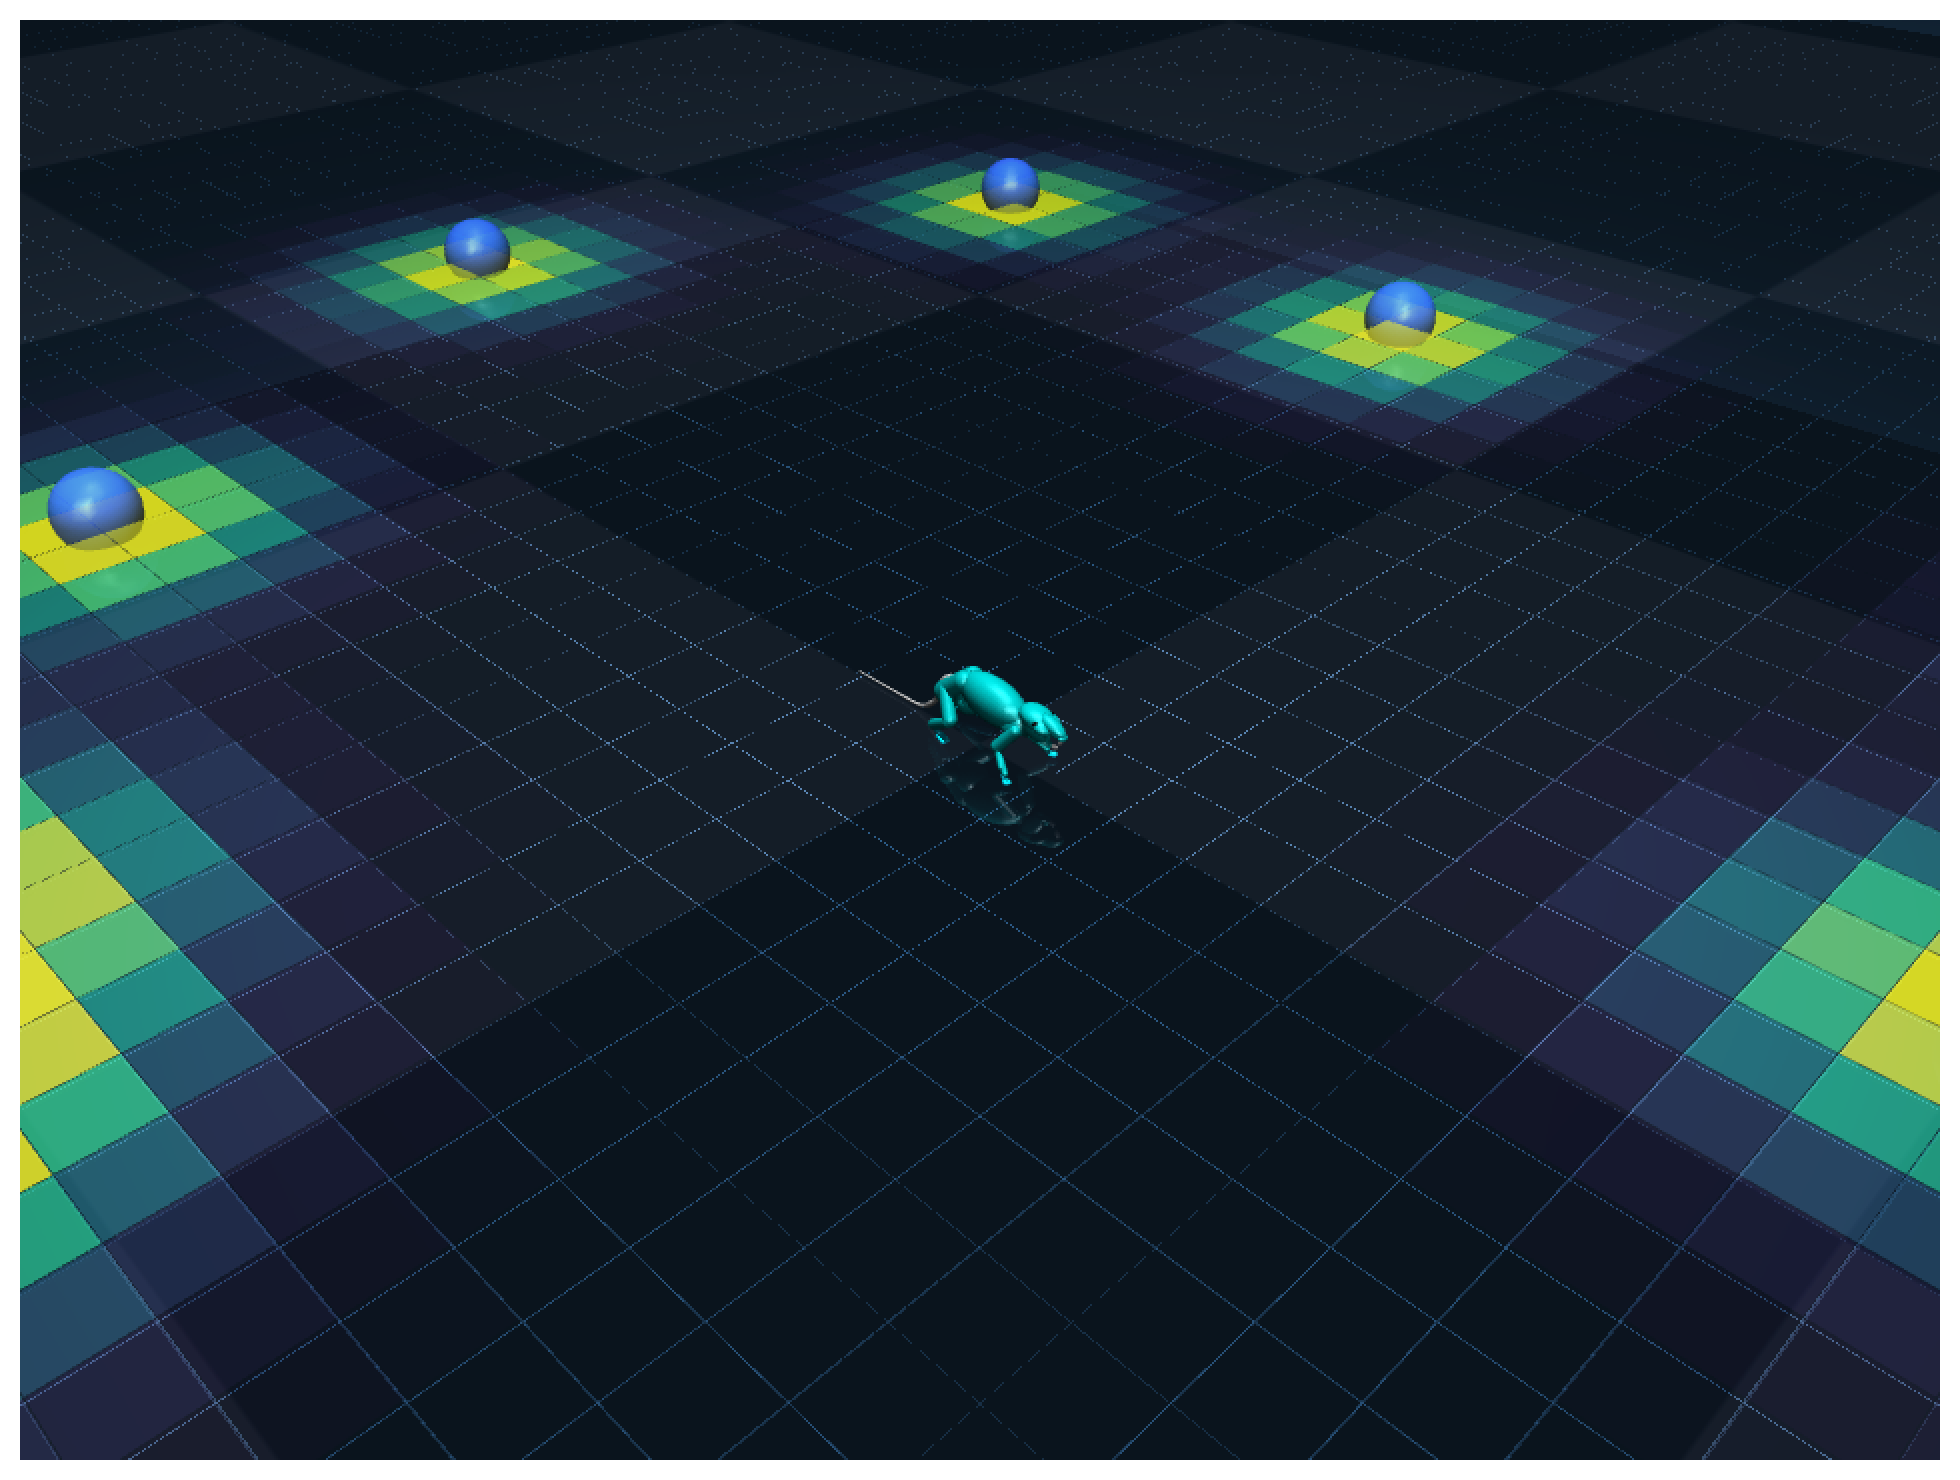

In [10]:
renderer = mujoco.Renderer(model, height=720, width=960)

cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.fixedcamid = -1
cam.trackbodyid = -1
cam.lookat[:] = [0, 0, 0]
cam.distance = 2.0
cam.azimuth = 135
cam.elevation = -35

renderer.update_scene(data, camera=cam)
frame = renderer.render()

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(frame)
ax.axis("off")

plt.tight_layout()

save_name = "arena_forage_angled_overview"
fig.savefig(OUTPUT_DIR / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / f"{save_name}.png", bbox_inches="tight", dpi=300)
print(f"Saved to {OUTPUT_DIR / save_name}.[pdf|svg|png]")

plt.show()
renderer.close()